In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:

df = pd.read_csv('sales_raw.csv')

print(df.head())


   transaction_id  sale_date region    category  quantity unit_price
0            1001  10/1/2026  North       food        2.0        120
1            1002  10/1/2026  South       Books       1.0        250
2            1003  10/2/2026  North        Food       3.0        110
3            1004  10/2/2026   East  Stationery       4.0         50
4            1005  10/3/2026  SOUTH       books       2.0        250


In [3]:

print("Dataset Shape:", df.shape)


Dataset Shape: (21, 6)


In [4]:

print("Column Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)


Column Names:
Index(['transaction_id', 'sale_date', 'region', 'category', 'quantity',
       'unit_price'],
      dtype='object')

Data Types:
transaction_id      int64
sale_date          object
region             object
category           object
quantity          float64
unit_price         object
dtype: object


In [5]:

print(df.isna().sum())


transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64


In [6]:

print("Duplicate Rows:", df.duplicated().sum())


Duplicate Rows: 1


In [7]:

# Create a copy of original dataset
df_clean = df.copy()

# Check original and copied data
print("Original Rows:", len(df))
print("Copied Rows:", len(df_clean))


Original Rows: 21
Copied Rows: 21


In [8]:

# Remove extra spaces and standardize text

df_clean['region'] = df_clean['region'].str.strip().str.title()

df_clean['category'] = df_clean['category'].str.strip().str.title()

# Display unique values
print("Regions:", df_clean['region'].unique())

print("Categories:", df_clean['category'].unique())


Regions: ['North' 'South' 'East' 'West' nan]
Categories: ['Food' 'Books' 'Stationery']


In [9]:

# Convert columns into numeric values

df_clean['quantity'] = pd.to_numeric(
    df_clean['quantity'], errors='coerce'
)

df_clean['unit_price'] = pd.to_numeric(
    df_clean['unit_price'], errors='coerce'
)

# Check missing values again
print(df_clean.isna().sum())


transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        2
dtype: int64


In [10]:

# Fill missing region with Unknown
df_clean['region'] = df_clean['region'].fillna('Unknown')


In [11]:

# Check duplicate rows
print("Duplicates Before:", df_clean.duplicated().sum())

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Check duplicates again
print("Duplicates After:", df_clean.duplicated().sum())


Duplicates Before: 1
Duplicates After: 0


In [12]:

# Convert sale_date into datetime
df_clean['sale_date'] = pd.to_datetime(
    df_clean['sale_date'],
    errors='coerce'
)

# Check invalid dates
print(df_clean[df_clean['sale_date'].isna()])


    transaction_id sale_date region category  quantity  unit_price
13            1014       NaT   West    Books       2.0       300.0


In [13]:

df_clean = df_clean.dropna(subset=['sale_date'])


In [14]:

# Remove rows with missing quantity or unit price
df_clean = df_clean.dropna(
    subset=['quantity', 'unit_price']
)

# Remove invalid non-positive quantity and price
df_clean = df_clean[
    (df_clean['quantity'] > 0) &
    (df_clean['unit_price'] > 0)
]

print("Missing Values After Cleaning:")
print(df_clean.isna().sum())


Missing Values After Cleaning:
transaction_id    0
sale_date         0
region            0
category          0
quantity          0
unit_price        0
dtype: int64


In [15]:

print(df_clean[df_clean['unit_price'] > 1000])


    transaction_id  sale_date region    category  quantity  unit_price
15            1016 2026-10-08  North  Stationery       1.0     10000.0


In [16]:

print("Rows Before Cleaning:", len(df))

print("Rows After Cleaning:", len(df_clean))

print("Rows Removed:", len(df) - len(df_clean))


Rows Before Cleaning: 21
Rows After Cleaning: 15
Rows Removed: 6


In [17]:

# Display cleaned dataset
print(df_clean.head(10))

# Check final shape
print("Final Shape:", df_clean.shape)

# Check data types
print(df_clean.dtypes)

# Check missing values
print(df_clean.isna().sum())

# Check duplicates
print("Duplicates:", df_clean.duplicated().sum())


    transaction_id  sale_date region    category  quantity  unit_price
0             1001 2026-10-01  North        Food       2.0       120.0
1             1002 2026-10-01  South       Books       1.0       250.0
2             1003 2026-10-02  North        Food       3.0       110.0
3             1004 2026-10-02   East  Stationery       4.0        50.0
4             1005 2026-10-03  South       Books       2.0       250.0
6             1007 2026-10-04  North  Stationery       3.0        60.0
7             1008 2026-10-04   East       Books       1.0       300.0
8             1009 2026-10-05   West        Food       5.0        90.0
11            1012 2026-10-06  North       Books       1.0       320.0
14            1015 2026-10-08   East        Food       2.0       120.0
Final Shape: (15, 6)
transaction_id             int64
sale_date         datetime64[ns]
region                    object
category                  object
quantity                 float64
unit_price               float64


### Data Cleaning Explanation

The raw sales dataset was cleaned using Pandas.

1. Extra spaces were removed from the region and category columns.
2. Text values were standardized using title case.
3. Missing region values were replaced with "Unknown".
4. Missing quantities and missing or invalid unit prices were removed because they could not be used for revenue calculations.
5. Duplicate records were removed using `drop_duplicates()`.
6. Invalid dates were converted to missing datetime values and removed.
7. Non-positive quantities and prices were removed.
8. The unusually high unit price of 10000 was retained for further investigation because there was insufficient evidence to classify it as an error.

The dataset contained 21 rows before cleaning and 15 rows after cleaning. Therefore, 6 rows were removed.

In [18]:

# Calculate revenue

df_clean['revenue'] = (
    df_clean['quantity'] * df_clean['unit_price']
)

# Display first five rows
print(df_clean.head())


   transaction_id  sale_date region    category  quantity  unit_price  revenue
0            1001 2026-10-01  North        Food       2.0       120.0    240.0
1            1002 2026-10-01  South       Books       1.0       250.0    250.0
2            1003 2026-10-02  North        Food       3.0       110.0    330.0
3            1004 2026-10-02   East  Stationery       4.0        50.0    200.0
4            1005 2026-10-03  South       Books       2.0       250.0    500.0


In [19]:

total_revenue = df_clean['revenue'].sum()

print("Total Sales Revenue:", total_revenue)


Total Sales Revenue: 14175.0


In [20]:

# Group revenue by region

region_sales = df_clean.groupby('region')['revenue'].sum()

print(region_sales)


region
East         740.0
North      11470.0
South       1035.0
Unknown      400.0
West         530.0
Name: revenue, dtype: float64


In [21]:

region_sales = (
    df_clean.groupby('region', as_index=False)['revenue']
    .sum()
)

# Sort revenue from highest to lowest
region_sales = region_sales.sort_values(
    by='revenue',
    ascending=False
)

print(region_sales)


    region  revenue
1    North  11470.0
2    South   1035.0
0     East    740.0
4     West    530.0
3  Unknown    400.0


In [22]:

# Group revenue by category

category_sales = (
    df_clean.groupby('category', as_index=False)['revenue']
    .sum()
)

# Sort highest to lowest
category_sales = category_sales.sort_values(
    by='revenue',
    ascending=False
)

print(category_sales)


     category  revenue
2  Stationery  10460.0
1        Food   1945.0
0       Books   1770.0


### Business Findings

**Finding 1: Region-wise Revenue**

The North region generated the highest revenue of 11,470, while the West region generated the lowest revenue of 530. This shows that sales revenue is not equally distributed across regions.

**Finding 2: Category-wise Revenue**

Stationery generated the highest revenue of 10,460, followed by Food at 1,945 and Books at 1,770. The unusually high Stationery revenue is significantly influenced by transaction ID 1016, which has a unit price of 10,000.

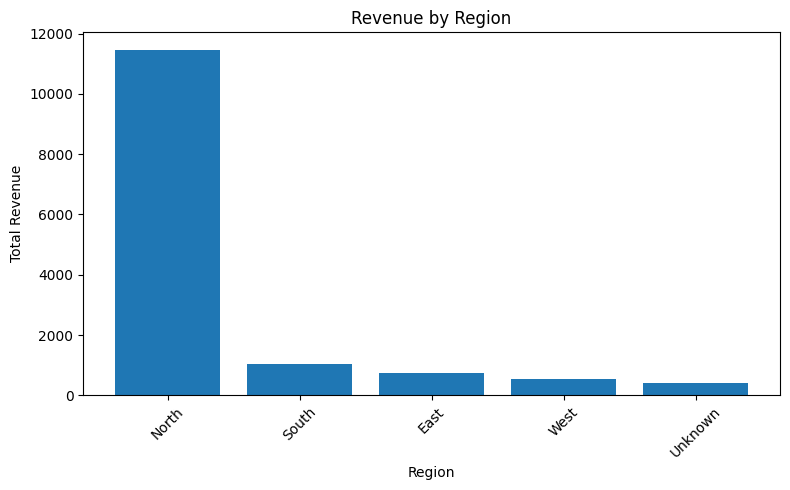

In [23]:

plt.figure(figsize=(8, 5))

plt.bar(
    region_sales['region'],
    region_sales['revenue']
)

plt.title('Revenue by Region')
plt.xlabel('Region')
plt.ylabel('Total Revenue')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


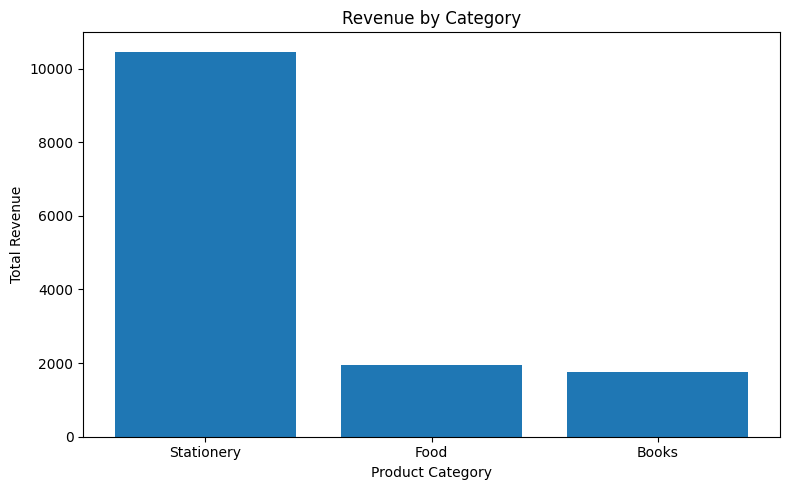

In [24]:

plt.figure(figsize=(8, 5))

plt.bar(
    category_sales['category'],
    category_sales['revenue']
)

plt.title('Revenue by Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

plt.tight_layout()
plt.show()


In [25]:

# Save cleaned dataset

df_clean.to_csv('cleaned_sales.csv', index=False)

print("cleaned_sales.csv saved successfully!")


cleaned_sales.csv saved successfully!


In [26]:

# Read saved file again

cleaned_check = pd.read_csv('cleaned_sales.csv')

print(cleaned_check.head())
print("Shape:", cleaned_check.shape)


   transaction_id   sale_date region    category  quantity  unit_price  \
0            1001  2026-10-01  North        Food       2.0       120.0   
1            1002  2026-10-01  South       Books       1.0       250.0   
2            1003  2026-10-02  North        Food       3.0       110.0   
3            1004  2026-10-02   East  Stationery       4.0        50.0   
4            1005  2026-10-03  South       Books       2.0       250.0   

   revenue  
0    240.0  
1    250.0  
2    330.0  
3    200.0  
4    500.0  
Shape: (15, 7)


In [27]:

import pandas as pd

sales = pd.read_csv('cleaned_sales.csv')

print(sales.head())
print(sales.shape)


   transaction_id   sale_date region    category  quantity  unit_price  \
0            1001  2026-10-01  North        Food       2.0       120.0   
1            1002  2026-10-01  South       Books       1.0       250.0   
2            1003  2026-10-02  North        Food       3.0       110.0   
3            1004  2026-10-02   East  Stationery       4.0        50.0   
4            1005  2026-10-03  South       Books       2.0       250.0   

   revenue  
0    240.0  
1    250.0  
2    330.0  
3    200.0  
4    500.0  
(15, 7)


In [28]:

# Calculate 5% tax

sales['tax_amount'] = sales['revenue'] * 0.05

# Display first five rows
print(sales.head())


   transaction_id   sale_date region    category  quantity  unit_price  \
0            1001  2026-10-01  North        Food       2.0       120.0   
1            1002  2026-10-01  South       Books       1.0       250.0   
2            1003  2026-10-02  North        Food       3.0       110.0   
3            1004  2026-10-02   East  Stationery       4.0        50.0   
4            1005  2026-10-03  South       Books       2.0       250.0   

   revenue  tax_amount  
0    240.0        12.0  
1    250.0        12.5  
2    330.0        16.5  
3    200.0        10.0  
4    500.0        25.0  


In [29]:

# Increase Books unit_price by 10%

sales.loc[
    sales['category'] == 'Books',
    'unit_price'
] *= 1.10

# Recalculate revenue
sales['revenue'] = sales['quantity'] * sales['unit_price']

# Recalculate tax
sales['tax_amount'] = sales['revenue'] * 0.05

# Display updated Books records
print(sales[sales['category'] == 'Books'])


    transaction_id   sale_date   region category  quantity  unit_price  \
1             1002  2026-10-01    South    Books       1.0       275.0   
4             1005  2026-10-03    South    Books       2.0       275.0   
6             1008  2026-10-04     East    Books       1.0       330.0   
8             1012  2026-10-06    North    Books       1.0       352.0   
12            1018  2026-10-09  Unknown    Books       2.0       220.0   

    revenue  tax_amount  
1     275.0       13.75  
4     550.0       27.50  
6     330.0       16.50  
8     352.0       17.60  
12    440.0       22.00  


In [30]:

# Select transaction ID to remove

selected_id = 1001

# Check selected transaction
print(sales[sales['transaction_id'] == selected_id])

# Remove selected transaction
sales = sales.loc[
    sales['transaction_id'] != selected_id
].copy()

print("Updated rows:", len(sales))


   transaction_id   sale_date region category  quantity  unit_price  revenue  \
0            1001  2026-10-01  North     Food       2.0       120.0    240.0   

   tax_amount  
0        12.0  
Updated rows: 14


In [31]:

# Create temporary column

sales['review_status'] = 'Pending'

print(sales.head())

# Remove temporary column

sales = sales.drop(columns=['review_status'])

# Verify column removed
print(sales.columns)


   transaction_id   sale_date region    category  quantity  unit_price  \
1            1002  2026-10-01  South       Books       1.0       275.0   
2            1003  2026-10-02  North        Food       3.0       110.0   
3            1004  2026-10-02   East  Stationery       4.0        50.0   
4            1005  2026-10-03  South       Books       2.0       275.0   
5            1007  2026-10-04  North  Stationery       3.0        60.0   

   revenue  tax_amount review_status  
1    275.0       13.75       Pending  
2    330.0       16.50       Pending  
3    200.0       10.00       Pending  
4    550.0       27.50       Pending  
5    180.0        9.00       Pending  
Index(['transaction_id', 'sale_date', 'region', 'category', 'quantity',
       'unit_price', 'revenue', 'tax_amount'],
      dtype='object')


In [32]:

# Save final updated CSV

sales.to_csv('sales_updated.csv', index=False)

print("sales_updated.csv saved successfully!")


sales_updated.csv saved successfully!


In [33]:

# Read updated CSV again

final_sales = pd.read_csv('sales_updated.csv')

# Display first five rows
print(final_sales.head())

# Display final column names
print("\nFinal Column Names:")
print(final_sales.columns.tolist())

# Display final shape
print("\nFinal Shape:", final_sales.shape)


   transaction_id   sale_date region    category  quantity  unit_price  \
0            1002  2026-10-01  South       Books       1.0       275.0   
1            1003  2026-10-02  North        Food       3.0       110.0   
2            1004  2026-10-02   East  Stationery       4.0        50.0   
3            1005  2026-10-03  South       Books       2.0       275.0   
4            1007  2026-10-04  North  Stationery       3.0        60.0   

   revenue  tax_amount  
0    275.0       13.75  
1    330.0       16.50  
2    200.0       10.00  
3    550.0       27.50  
4    180.0        9.00  

Final Column Names:
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']

Final Shape: (14, 8)


In [36]:

readme_content = """# Sunday Project – Data Quality, Insights & CSV Operations

## Project Overview
This project is part of AI Engineering Bootcamp Module 02.

The purpose of this project is to clean raw sales data, perform revenue analysis, create charts, and manipulate CSV files using Python and Pandas.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

## Part A – Data Quality & Basic Insights
- Loaded and inspected sales_raw.csv.
- Checked missing values and duplicates.
- Cleaned inconsistent and invalid data.
- Calculated revenue.
- Performed GroupBy analysis.
- Created two charts.
- Wrote two business findings.
- Saved cleaned_sales.csv.

## Part B – CSV File Handling
- Loaded cleaned_sales.csv.
- Calculated 5% tax.
- Increased Books prices by 10%.
- Removed one transaction.
- Created and removed review_status.
- Saved sales_updated.csv.

## Project Files
- sales_raw.csv
- cleaned_sales.csv
- sales_updated.csv
- Sunday_Project.ipynb
- README.md

## How to Run
1. Open Google Colab.
2. Upload all project files.
3. Open Sunday_Project.ipynb.
4. Run all cells in order.

## GitHub Repository
Add your GitHub repository link here.

## Author
Student Name: Zeenat Fatima
Training ID: TRN-2026-000852

AI Engineering Bootcamp - Module 02
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")


README.md created successfully!


In [37]:

with open("README.md", "r", encoding="utf-8") as file:
    print(file.read())


# Sunday Project – Data Quality, Insights & CSV Operations

## Project Overview
This project is part of AI Engineering Bootcamp Module 02.

The purpose of this project is to clean raw sales data, perform revenue analysis, create charts, and manipulate CSV files using Python and Pandas.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

## Part A – Data Quality & Basic Insights
- Loaded and inspected sales_raw.csv.
- Checked missing values and duplicates.
- Cleaned inconsistent and invalid data.
- Calculated revenue.
- Performed GroupBy analysis.
- Created two charts.
- Wrote two business findings.
- Saved cleaned_sales.csv.

## Part B – CSV File Handling
- Loaded cleaned_sales.csv.
- Calculated 5% tax.
- Increased Books prices by 10%.
- Removed one transaction.
- Created and removed review_status.
- Saved sales_updated.csv.

## Project Files
- sales_raw.csv
- cleaned_sales.csv
- sales_updated.csv
- Sunday_Project.ipynb
- README.md

## How to Run
1. Open Goo

In [38]:

import os

# Check all required files
required_files = [
    'sales_raw.csv',
    'cleaned_sales.csv',
    'sales_updated.csv',
    'README.md'
]

for file in required_files:
    if os.path.exists(file):
        print("Available:", file)
    else:
        print("Missing:", file)


Available: sales_raw.csv
Available: cleaned_sales.csv
Available: sales_updated.csv
Available: README.md
